In [1]:
import numpy as np
import pandas as pd
import seaborn as sns
import matplotlib.pyplot as plt
from sklearn.preprocessing import LabelEncoder
from sklearn.model_selection import train_test_split
from xgboost import XGBRegressor
from sklearn import metrics
import warnings 
warnings.filterwarnings('ignore')

In [2]:
df = pd.read_csv('Train.csv')

In [3]:
df.head()

,Item_Identifier,Item_Weight,Item_Fat_Content,Item_Visibility,Item_Type,Item_MRP,Outlet_Identifier,Outlet_Establishment_Year,Outlet_Size,Outlet_Location_Type,Outlet_Type,Item_Outlet_Sales
0,FDA15,9.30,Low Fat,0.016047,Dairy,249.8092,OUT049,1999,Medium,Tier 1,Supermarket Type1,3735.1380
1,DRC01,5.92,Regular,0.019278,Soft Drinks,48.2692,OUT018,2009,Medium,Tier 3,Supermarket Type2,443.4228
2,FDN15,17.50,Low Fat,0.016760,Meat,141.6180,OUT049,1999,Medium,Tier 1,Supermarket Type1,2097.2700
3,FDX07,19.20,Regular,0.000000,Fruits and Vegetables,182.0950,OUT010,1998,NaN,Tier 3,Grocery Store,732.3800
4,NCD19,8.93,Low Fat,0.000000,Household,53.8614,OUT013,1987,High,Tier 3,Supermarket Type1,994.7052


In [4]:
df.shape

(8523, 12)

Data Cleaning

In [5]:
df.duplicated().sum()

0

In [6]:
df.info()

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 8523 entries, 0 to 8522
Data columns (total 12 columns):
 #   Column                     Non-Null Count  Dtype  
---  ------                     --------------  -----  
 0   Item_Identifier            8523 non-null   object 
 1   Item_Weight                7060 non-null   float64
 2   Item_Fat_Content           8523 non-null   object 
 3   Item_Visibility            8523 non-null   float64
 4   Item_Type                  8523 non-null   object 
 5   Item_MRP                   8523 non-null   float64
 6   Outlet_Identifier          8523 non-null   object 
 7   Outlet_Establishment_Year  8523 non-null   int64  
 8   Outlet_Size                6113 non-null   object 
 9   Outlet_Location_Type       8523 non-null   object 
 10  Outlet_Type                8523 non-null   object 
 11  Item_Outlet_Sales          8523 non-null   float64
dtypes: float64(4), int64(1), object(7)
memory usage: 799.2+ KB


There are only 2 columns with missing values that is 'Item_Weight' and 'Outlet_Size'

In [7]:
df.isnull().sum()

Item_Identifier                 0
Item_Weight                  1463
Item_Fat_Content                0
Item_Visibility                 0
Item_Type                       0
Item_MRP                        0
Outlet_Identifier               0
Outlet_Establishment_Year       0
Outlet_Size                  2410
Outlet_Location_Type            0
Outlet_Type                     0
Item_Outlet_Sales               0
dtype: int64

Since there are 1463 missing values for Item_Weight we will groupby Item_type with Item_Weight and take the mean of Item_Weight with respect to evry Item_Type and fill those missing values

In [8]:
df.groupby('Item_Type')['Item_Weight'].mean()

Item_Type
Baking Goods             12.277108
Breads                   11.346936
Breakfast                12.768202
Canned                   12.305705
Dairy                    13.426069
Frozen Foods             12.867061
Fruits and Vegetables    13.224769
Hard Drinks              11.400328
Health and Hygiene       13.142314
Household                13.384736
Meat                     12.817344
Others                   13.853285
Seafood                  12.552843
Snack Foods              12.987880
Soft Drinks              11.847460
Starchy Foods            13.690731
Name: Item_Weight, dtype: float64

In [9]:
df['Item_Weight']= df.groupby('Item_Type')['Item_Weight'].apply(lambda x:x.fillna(x.mean()))

In [10]:
df.info()

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 8523 entries, 0 to 8522
Data columns (total 12 columns):
 #   Column                     Non-Null Count  Dtype  
---  ------                     --------------  -----  
 0   Item_Identifier            8523 non-null   object 
 1   Item_Weight                8523 non-null   float64
 2   Item_Fat_Content           8523 non-null   object 
 3   Item_Visibility            8523 non-null   float64
 4   Item_Type                  8523 non-null   object 
 5   Item_MRP                   8523 non-null   float64
 6   Outlet_Identifier          8523 non-null   object 
 7   Outlet_Establishment_Year  8523 non-null   int64  
 8   Outlet_Size                6113 non-null   object 
 9   Outlet_Location_Type       8523 non-null   object 
 10  Outlet_Type                8523 non-null   object 
 11  Item_Outlet_Sales          8523 non-null   float64
dtypes: float64(4), int64(1), object(7)
memory usage: 799.2+ KB


In [11]:
df['Outlet_Size'].mode()

0    Medium
dtype: object

Similarly again for Outlet_Size i will take mode of Outlet_type and fill the missing values of Outlet_Size with respect to the mode of outlet_type

In [12]:
df['Outlet_Size'].value_counts()

Medium    2793
Small     2388
High       932
Name: Outlet_Size, dtype: int64

In [13]:
mode_of_outlet_size = df.pivot_table(values='Outlet_Size',columns='Outlet_Type',aggfunc=(lambda x:x.mode()[0]))

In [14]:
mode_of_outlet_size

Outlet_Type,Grocery Store,Supermarket Type1,Supermarket Type2,Supermarket Type3
Outlet_Size,Small,Small,Medium,Medium


In [15]:
missing_values = df['Outlet_Size'].isnull()

In [16]:
missing_values

0       False
1       False
2       False
3        True
4       False
        ...  
8518    False
8519     True
8520    False
8521    False
8522    False
Name: Outlet_Size, Length: 8523, dtype: bool

In [17]:
df.loc[missing_values,'Outlet_Size'] = df.loc[missing_values,'Outlet_Type'].apply(lambda x: mode_of_outlet_size[x].Outlet_Size)

In [18]:
df.info()

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 8523 entries, 0 to 8522
Data columns (total 12 columns):
 #   Column                     Non-Null Count  Dtype  
---  ------                     --------------  -----  
 0   Item_Identifier            8523 non-null   object 
 1   Item_Weight                8523 non-null   float64
 2   Item_Fat_Content           8523 non-null   object 
 3   Item_Visibility            8523 non-null   float64
 4   Item_Type                  8523 non-null   object 
 5   Item_MRP                   8523 non-null   float64
 6   Outlet_Identifier          8523 non-null   object 
 7   Outlet_Establishment_Year  8523 non-null   int64  
 8   Outlet_Size                8523 non-null   object 
 9   Outlet_Location_Type       8523 non-null   object 
 10  Outlet_Type                8523 non-null   object 
 11  Item_Outlet_Sales          8523 non-null   float64
dtypes: float64(4), int64(1), object(7)
memory usage: 799.2+ KB


In [19]:
print(df['Outlet_Size'].value_counts(dropna=False))

Small     4798
Medium    2793
High       932
Name: Outlet_Size, dtype: int64


In [20]:
df['Outlet_Type'].unique()

array(['Supermarket Type1', 'Supermarket Type2', 'Grocery Store',
       'Supermarket Type3'], dtype=object)

Categorical Standarization:

In [21]:
df['Item_Fat_Content'].unique()

array(['Low Fat', 'Regular', 'low fat', 'LF', 'reg'], dtype=object)

In [22]:
df['Item_Fat_Content']=df['Item_Fat_Content'].replace({"low fat":'Low Fat','LF':'Low Fat','reg':'Regular'})

In [23]:
df['Item_Fat_Content'].unique()

array(['Low Fat', 'Regular'], dtype=object)

In [24]:
df.to_csv("BigMart_Cleaned.csv", index=False)

Data Analysis

In [25]:
df.describe()

,Item_Weight,Item_Visibility,Item_MRP,Outlet_Establishment_Year,Item_Outlet_Sales
count,8523.000000,8523.000000,8523.000000,8523.000000,8523.000000
mean,12.857890,0.066132,140.992782,1997.831867,2181.288914
std,4.232804,0.051598,62.275067,8.371760,1706.499616
min,4.555000,0.000000,31.290000,1985.000000,33.290000
25%,9.310000,0.026989,93.826500,1987.000000,834.247400
50%,12.867061,0.053931,143.012800,1999.000000,1794.331000
75%,16.000000,0.094585,185.643700,2004.000000,3101.296400
max,21.350000,0.328391,266.888400,2009.000000,13086.964800


In [26]:
df.skew()

Item_Weight                  0.089537
Item_Visibility              1.167091
Item_MRP                     0.127202
Outlet_Establishment_Year   -0.396641
Item_Outlet_Sales            1.177531
dtype: float64

Numerical Features

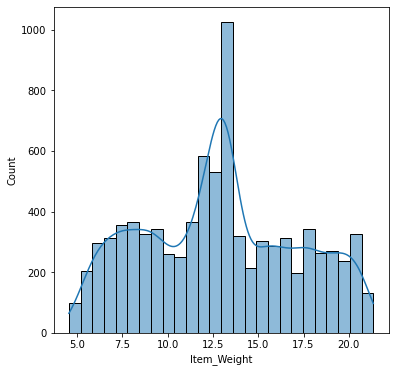

In [27]:
plt.figure(figsize=(6,6))
sns.histplot(df['Item_Weight'],kde=True)
plt.show()

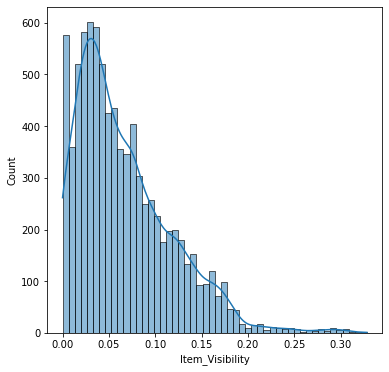

In [28]:
plt.figure(figsize=(6,6))
sns.histplot(df['Item_Visibility'],kde=True)
plt.show()

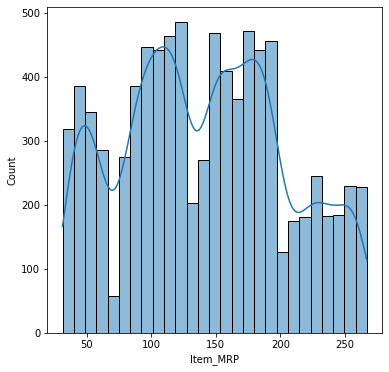

In [29]:
plt.figure(figsize=(6,6))
sns.histplot(df['Item_MRP'],kde=True)
plt.show()

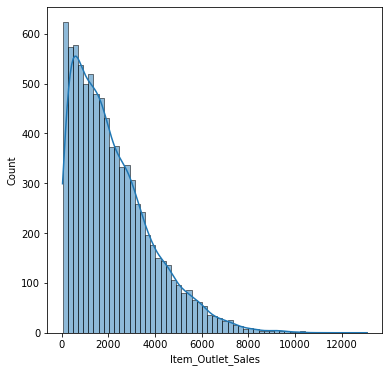

In [30]:
plt.figure(figsize=(6,6))
sns.histplot(df['Item_Outlet_Sales'],kde=True)
plt.show()

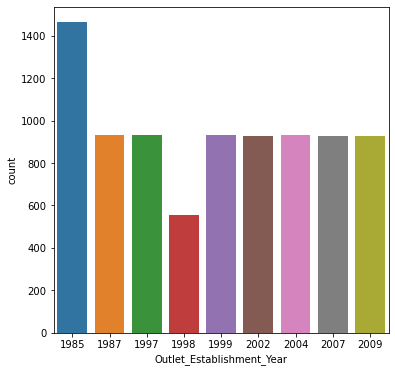

In [31]:
plt.figure(figsize=(6,6))
sns.countplot(df['Outlet_Establishment_Year'])
plt.show()

Categorical Features

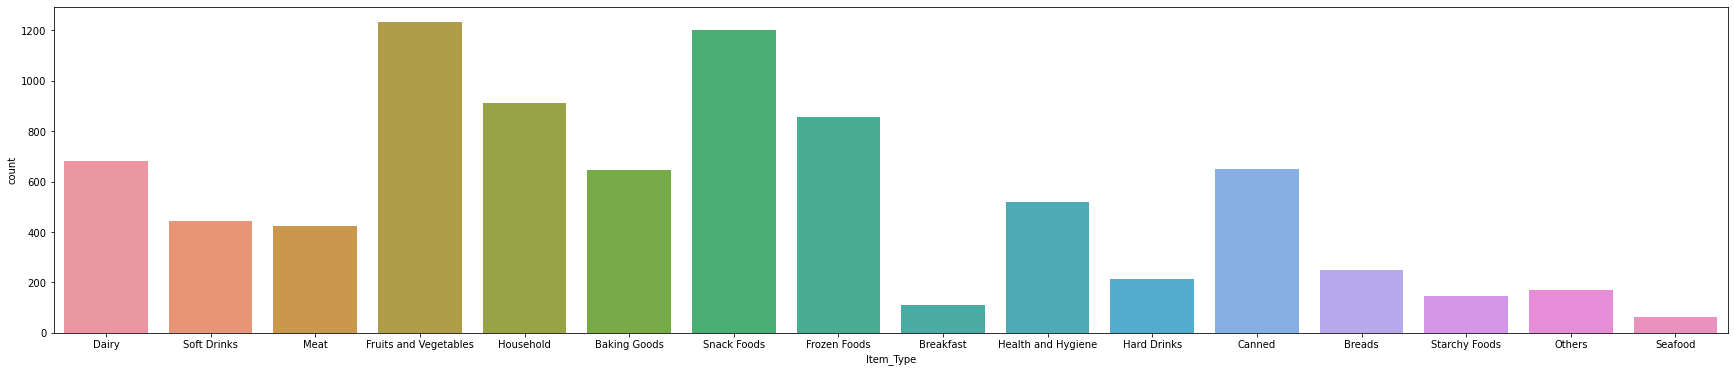

In [32]:
plt.figure(figsize=(30,6))
sns.countplot(df['Item_Type'])
plt.show()

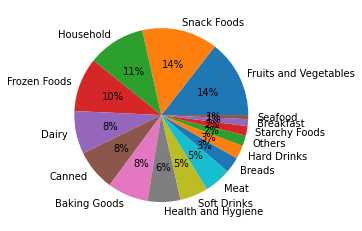

In [33]:
a= df['Item_Type'].value_counts()
plt.pie(a,data=df,labels= a.index,autopct='%.0f%%')
plt.show()

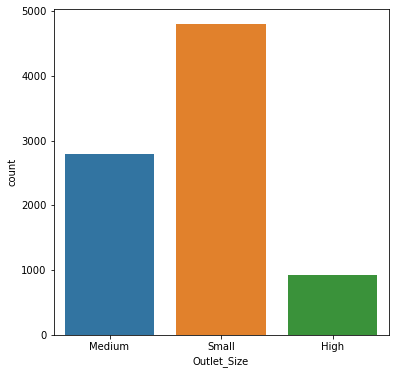

In [34]:
plt.figure(figsize=(6,6))
sns.countplot(df['Outlet_Size'])
plt.show()

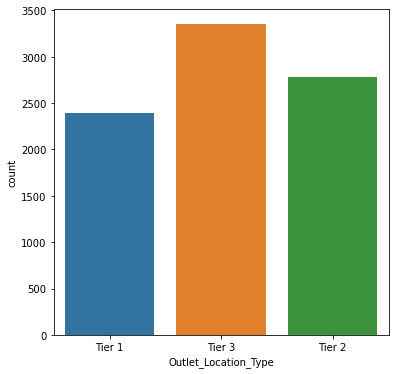

In [35]:
plt.figure(figsize=(6,6))
sns.countplot('Outlet_Location_Type',data=df)
plt.show()

In [36]:
print(df['Item_Fat_Content'].value_counts(dropna=False))

Low Fat    5517
Regular    3006
Name: Item_Fat_Content, dtype: int64


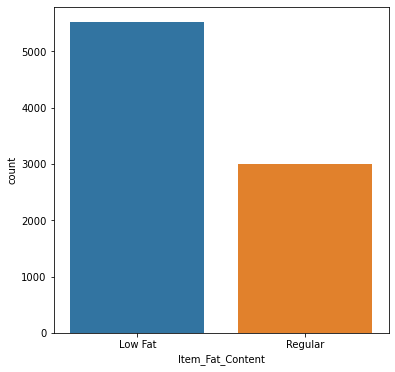

In [37]:
plt.figure(figsize=(6,6))
sns.countplot(df['Item_Fat_Content'])
plt.show()

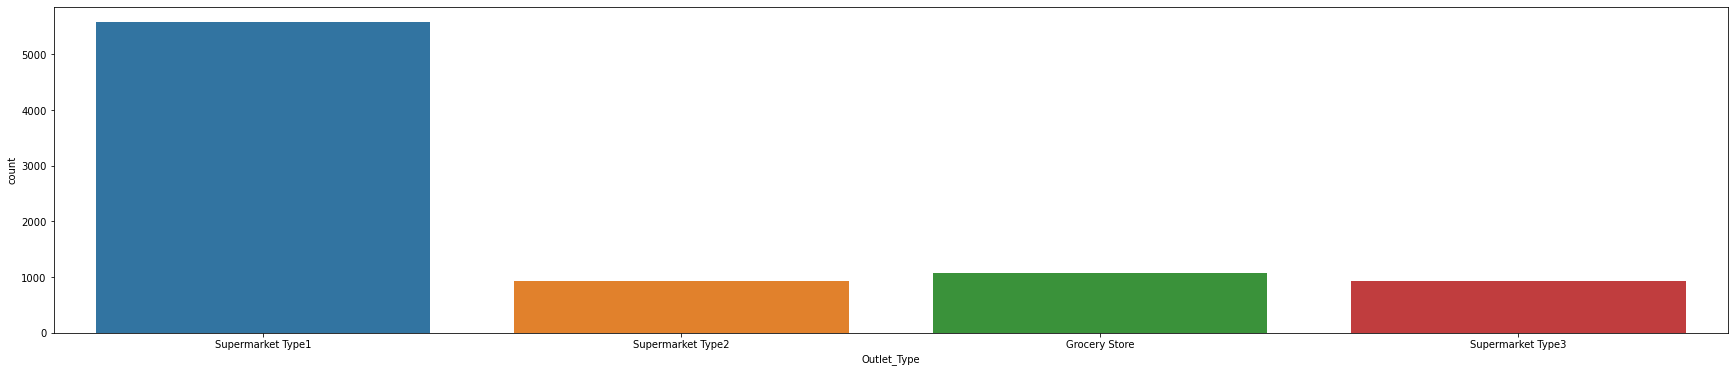

In [38]:
plt.figure(figsize=(30,6))
sns.countplot(df['Outlet_Type'])
plt.show()

Bivariate Analysis

<AxesSubplot:xlabel='Item_Type', ylabel='Item_Outlet_Sales'>

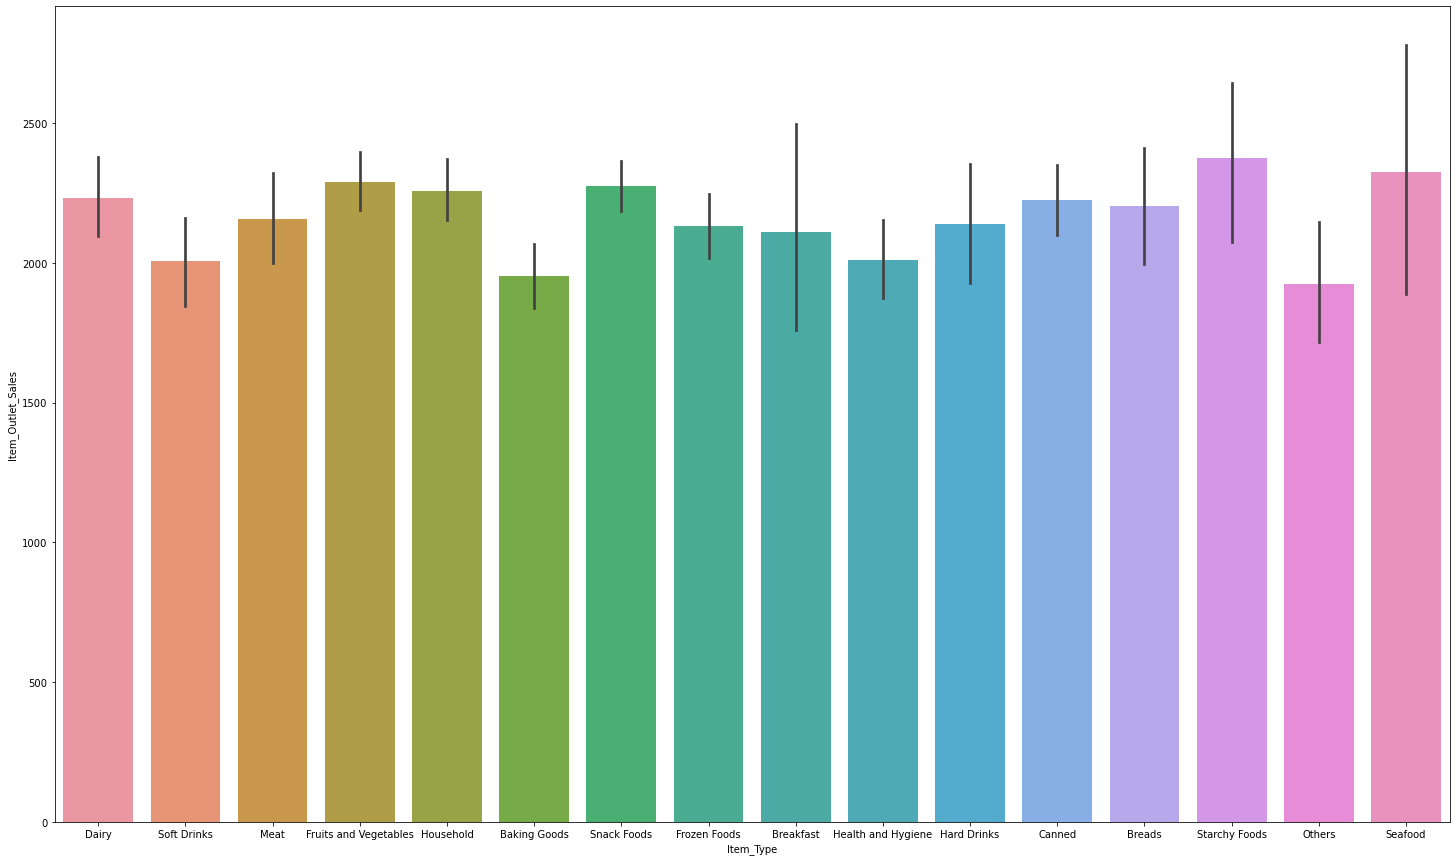

In [39]:
plt.figure(figsize = (25,15))
sns.barplot(y="Item_Outlet_Sales", x="Item_Type", data=df)

Text(0.5, 0, 'Item Visibility')

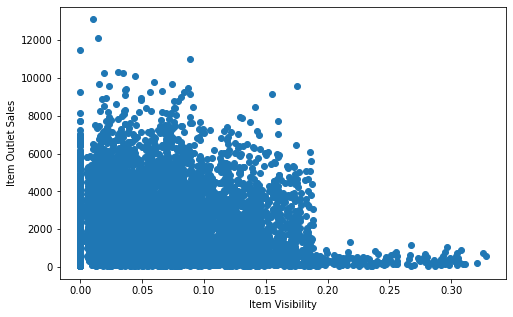

In [40]:
plt.figure(figsize=(8,5))
plt.scatter(x='Item_Visibility',y='Item_Outlet_Sales',data=df)
plt.ylabel('Item Outlet Sales')
plt.xlabel('Item Visibility')

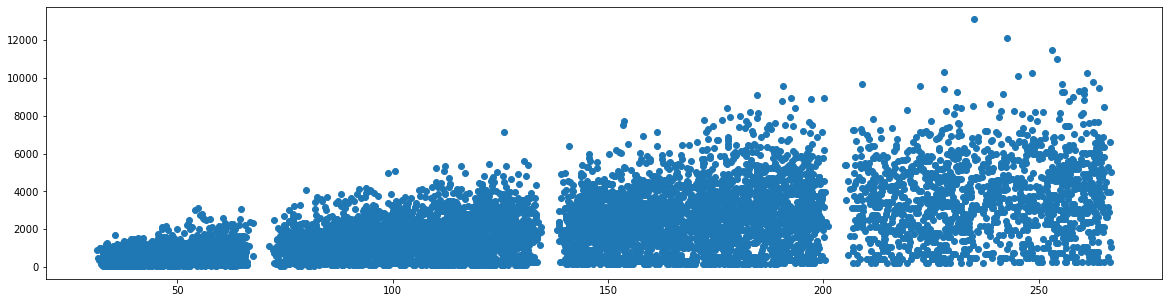

In [41]:
plt.figure(figsize =(20,5))
plt.scatter(x = 'Item_MRP', y = 'Item_Outlet_Sales',data = df )

<AxesSubplot:xlabel='Outlet_Location_Type', ylabel='Item_Outlet_Sales'>

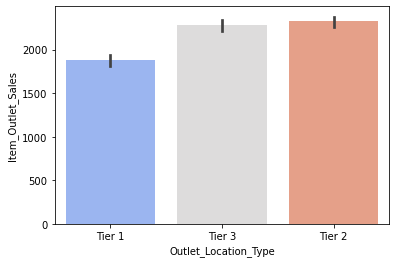

In [42]:
plt.figure(figsize = (6,4))
sns.barplot(x = 'Outlet_Location_Type',y = 'Item_Outlet_Sales',data =  df,palette='coolwarm')

<AxesSubplot:xlabel='Outlet_Size', ylabel='Item_Outlet_Sales'>

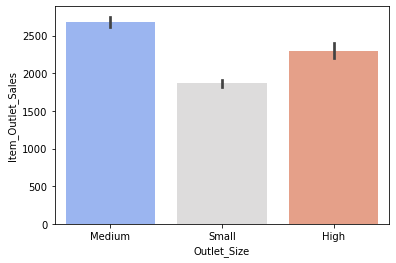

In [43]:
plt.figure(figsize = (6,4))
sns.barplot(x = 'Outlet_Size',y = 'Item_Outlet_Sales',data = df,palette='coolwarm')

<AxesSubplot:xlabel='Outlet_Type', ylabel='Item_Outlet_Sales'>

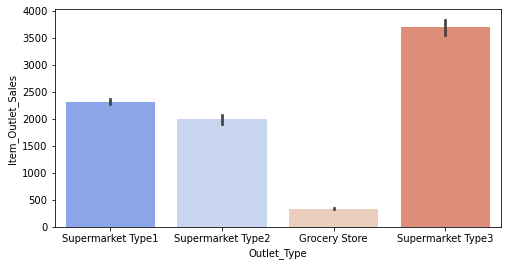

In [44]:
plt.figure(figsize = (8,4))
sns.barplot(x = 'Outlet_Type',y = 'Item_Outlet_Sales',data = df,palette='coolwarm')

Correlation Analysis and Heatmap

In [45]:
df.corr().iloc[ : , -1]

Item_Weight                  0.012088
Item_Visibility             -0.128625
Item_MRP                     0.567574
Outlet_Establishment_Year   -0.049135
Item_Outlet_Sales            1.000000
Name: Item_Outlet_Sales, dtype: float64

<AxesSubplot:>

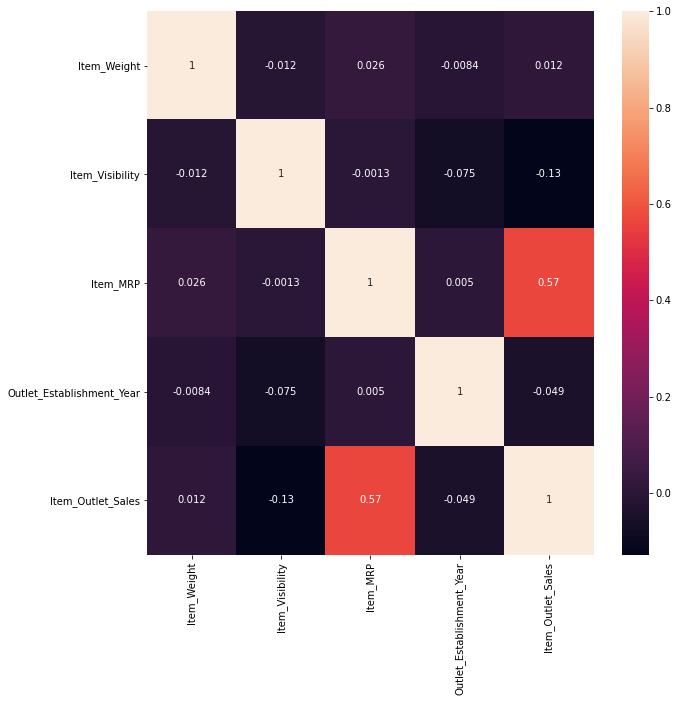

In [46]:
plt.figure(figsize = (10,10))
sns.heatmap(df.corr(),annot = True)

Data Preprocessing

In [47]:
len(df['Item_Identifier'].unique())

1559

In [48]:
len(df['Outlet_Identifier'].unique())

10

In [49]:
df.drop('Item_Identifier',axis=1,inplace=True)

In [50]:
df = pd.get_dummies(df, drop_first=True)

In [51]:
df.shape

(8523, 37)

Splitting features and Target

In [52]:
X=df.drop('Item_Outlet_Sales', axis=1)
y=df['Item_Outlet_Sales']

In [53]:
X_train , X_test, y_train , y_test = train_test_split(X,y, test_size= 0.2, random_state =2)

Basemodel of Linear Regression

In [54]:
from sklearn.linear_model import LinearRegression

In [55]:
model= LinearRegression()

In [56]:
model.fit(X_train,y_train)

LinearRegression()

In [57]:
y_pred= model.predict(X_test)

In [58]:
print(metrics.r2_score(y_test,y_pred))
print(metrics.mean_absolute_error(y_test,y_pred))
print(np.sqrt(metrics.mean_squared_error(y_test, y_pred)))

0.5446993922201375
875.6686491198152
1185.557671282402


Text(0.5, 1.0, 'Actual vs Predicted Sales (Linear Regression)')

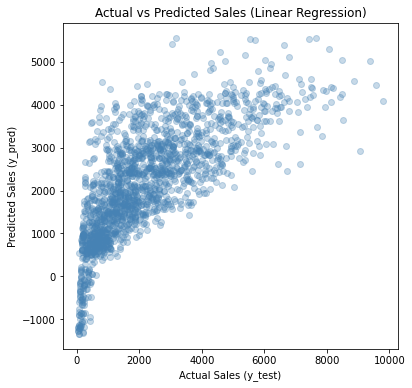

In [59]:
plt.figure(figsize=(6, 6))
plt.scatter(y_test, y_pred, alpha=0.3, color='steelblue')
plt.xlabel("Actual Sales (y_test)")
plt.ylabel("Predicted Sales (y_pred)")
plt.title("Actual vs Predicted Sales (Linear Regression)")

XG Boost Model

In [60]:
regressor = XGBRegressor()

In [61]:
regressor.fit(X_train,y_train)

XGBRegressor(base_score=0.5, booster='gbtree', colsample_bylevel=1,
             colsample_bynode=1, colsample_bytree=1, enable_categorical=False,
             gamma=0, gpu_id=-1, importance_type=None,
             interaction_constraints='', learning_rate=0.300000012,
             max_delta_step=0, max_depth=6, min_child_weight=1, missing=nan,
             monotone_constraints='()', n_estimators=100, n_jobs=4,
             num_parallel_tree=1, predictor='auto', random_state=0, reg_alpha=0,
             reg_lambda=1, scale_pos_weight=1, subsample=1, tree_method='exact',
             validate_parameters=1, verbosity=None)

In [62]:
y_pred_reg = regressor.predict(X_test)

In [63]:
print(metrics.r2_score(y_test,y_pred_reg))
print(metrics.mean_absolute_error(y_test,y_pred_reg))
print(np.sqrt(metrics.mean_squared_error(y_test, y_pred_reg)))

0.535990233725325
834.5385391913436
1196.8428530409994


Using Feature Importance

In [64]:
regressor.feature_importances_

array([0.00608784, 0.00809768, 0.04474314, 0.04324777, 0.00723349,
       0.00458316, 0.0094859 , 0.00937751, 0.00723618, 0.00502999,
       0.00817371, 0.00667312, 0.00482267, 0.00815721, 0.0078522 ,
       0.00599206, 0.01012326, 0.01156912, 0.00828395, 0.0117992 ,
       0.01041212, 0.01169622, 0.        , 0.01222257, 0.41331983,
       0.00835121, 0.00620738, 0.0083909 , 0.00716116, 0.00560936,
       0.00663001, 0.00545715, 0.00590259, 0.27007037, 0.        ,
       0.        ], dtype=float32)

In [65]:
feat_imp = pd.DataFrame({'importance':regressor.feature_importances_},index= X.columns ).sort_values('importance')

In [66]:
feat_imp

,importance
Outlet_Type_Supermarket Type3,0.000000
Outlet_Identifier_OUT018,0.000000
Outlet_Type_Supermarket Type2,0.000000
Item_Type_Breads,0.004583
Item_Type_Health and Hygiene,0.004823
Item_Type_Frozen Foods,0.005030
Outlet_Location_Type_Tier 2,0.005457
Outlet_Size_Medium,0.005609
Outlet_Location_Type_Tier 3,0.005903
Item_Type_Others,0.005992


In [67]:
df=df[['Outlet_Identifier_OUT027','Outlet_Type_Supermarket Type1','Item_MRP','Outlet_Establishment_Year','Outlet_Identifier_OUT019','Item_Type_Starchy Foods','Outlet_Identifier_OUT017','Item_Type_Snack Foods','Outlet_Identifier_OUT013','Item_Type_Seafood','Item_Type_Breakfast','Item_Type_Canned','Outlet_Identifier_OUT046','Item_Outlet_Sales']]

In [68]:
X= df.drop('Item_Outlet_Sales', axis=1)

In [69]:
y=df['Item_Outlet_Sales']

In [70]:
X_train, X_test, y_train, y_test = train_test_split(X,y,test_size = 0.2,random_state=2)

In [71]:
regressor = XGBRegressor()

In [72]:
regressor.fit(X_train,y_train)

XGBRegressor(base_score=0.5, booster='gbtree', colsample_bylevel=1,
             colsample_bynode=1, colsample_bytree=1, enable_categorical=False,
             gamma=0, gpu_id=-1, importance_type=None,
             interaction_constraints='', learning_rate=0.300000012,
             max_delta_step=0, max_depth=6, min_child_weight=1, missing=nan,
             monotone_constraints='()', n_estimators=100, n_jobs=4,
             num_parallel_tree=1, predictor='auto', random_state=0, reg_alpha=0,
             reg_lambda=1, scale_pos_weight=1, subsample=1, tree_method='exact',
             validate_parameters=1, verbosity=None)

In [73]:
y_pred_reg = regressor.predict(X_test)

In [74]:
print(metrics.r2_score(y_test,y_pred_reg))
print(metrics.mean_absolute_error(y_test,y_pred_reg))
print(np.sqrt(metrics.mean_squared_error(y_test, y_pred_reg)))

0.5424220998801578
826.2313389049918
1188.5188948971906


Text(0.5, 1.0, 'Actual vs Predicted Sales')

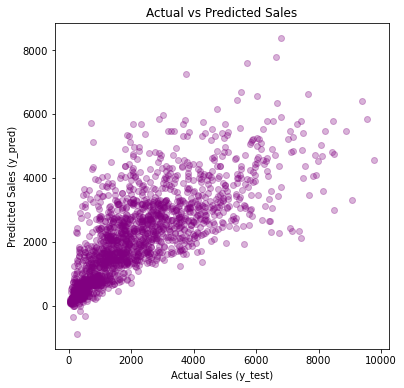

In [75]:
plt.figure(figsize=(6, 6))
plt.scatter(y_test, y_pred_reg, alpha=0.3, color='purple')
plt.xlabel("Actual Sales (y_test)")
plt.ylabel("Predicted Sales (y_pred)")
plt.title("Actual vs Predicted Sales") 

Using Hyperparametric Tuning

In [76]:
from sklearn.model_selection import RandomizedSearchCV
from scipy.stats import randint, uniform

In [77]:
param_dist = {
    'n_estimators': randint(100, 501),
    'max_depth': randint(3, 8),
    'learning_rate': uniform(0.01, 0.19),
    'subsample': uniform(0.7, 0.3),
    'colsample_bytree': uniform(0.7, 0.3)
}

In [78]:
random_search = RandomizedSearchCV(estimator=XGBRegressor(random_state=2),
    param_distributions=param_dist,
    n_iter=20,
    scoring='neg_mean_squared_error',
    cv=5,
    verbose=1,
    random_state=2,
    n_jobs=-1)

In [79]:
random_search.fit(X_train, y_train)

Fitting 5 folds for each of 20 candidates, totalling 100 fits


[Parallel(n_jobs=-1)]: Using backend LokyBackend with 4 concurrent workers.
[Parallel(n_jobs=-1)]: Done  42 tasks      | elapsed:  1.1min
[Parallel(n_jobs=-1)]: Done 100 out of 100 | elapsed:  2.2min finished


RandomizedSearchCV(cv=5,
                   estimator=XGBRegressor(base_score=None, booster=None,
                                          colsample_bylevel=None,
                                          colsample_bynode=None,
                                          colsample_bytree=None,
                                          enable_categorical=False, gamma=None,
                                          gpu_id=None, importance_type=None,
                                          interaction_constraints=None,
                                          learning_rate=None,
                                          max_delta_step=None, max_depth=None,
                                          min_child_weight=None, missing=nan,
                                          monotone_constraints=...
                                        'learning_rate': <scipy.stats._distn_infrastructure.rv_frozen object at 0x000001BEB7312670>,
                                        'max_depth': <scip

In [80]:
print("Best Parameters:", random_search.best_params_)
print("Best CV Score:", random_search.best_score_)

Best Parameters: {'colsample_bytree': 0.9119626017621751, 'learning_rate': 0.10139413358384991, 'max_depth': 3, 'n_estimators': 116, 'subsample': 0.8278067578168218}
Best CV Score: -1171981.740660557


In [81]:
best_model = random_search.best_estimator_

In [82]:
best_model

XGBRegressor(base_score=0.5, booster='gbtree', colsample_bylevel=1,
             colsample_bynode=1, colsample_bytree=0.9119626017621751,
             enable_categorical=False, gamma=0, gpu_id=-1, importance_type=None,
             interaction_constraints='', learning_rate=0.10139413358384991,
             max_delta_step=0, max_depth=3, min_child_weight=1, missing=nan,
             monotone_constraints='()', n_estimators=116, n_jobs=4,
             num_parallel_tree=1, predictor='auto', random_state=2, reg_alpha=0,
             reg_lambda=1, scale_pos_weight=1, subsample=0.8278067578168218,
             tree_method='exact', validate_parameters=1, verbosity=None)

In [83]:
y_pred_tuned = best_model.predict(X_test)

In [84]:
print("R2:", metrics.r2_score(y_test, y_pred_tuned))
print("MAE:", metrics.mean_absolute_error(y_test, y_pred_tuned))
print("RMSE:", np.sqrt(metrics.mean_squared_error(y_test, y_pred_tuned)))

R2: 0.5810585663350085
MAE: 800.0094643186508
RMSE: 1137.2350262954183


Text(0.5, 1.0, 'Actual vs Predicted Sales')

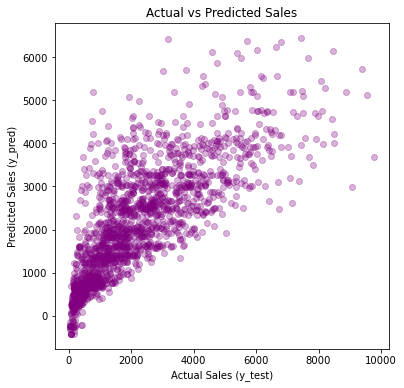

In [85]:
plt.figure(figsize=(6, 6))
plt.scatter(y_test, y_pred_tuned, alpha=0.3, color='purple')
plt.xlabel("Actual Sales (y_test)")
plt.ylabel("Predicted Sales (y_pred)")
plt.title("Actual vs Predicted Sales") 

Business Interpretation of Model Evaluation Metrics

The final tuned XGBoost model achieved an R² score of 0.5811, indicating that it explains approximately 58.1% of the variation in Item Outlet Sales. This suggests that the model has captured meaningful patterns from the available product and outlet characteristics.

The Mean Absolute Error (MAE) of 800.01 indicates that the model's predictions differ from actual sales by approximately 800 sales units on average. This provides an understandable measure of the model's prediction error.

The Root Mean Squared Error (RMSE) of 1137.24 indicates that larger prediction errors have a greater influence on the model's overall error. Such errors could be important for business operations because inaccurate sales estimates may affect inventory planning and product allocation.

From a business perspective, the model could assist BigMart in estimating product sales across different outlets and supporting inventory-related decisions. However, the model does not explain all variations in sales, and its predictions should be used as decision-support estimates rather than exact sales figures.